# DSA80003: Data Mining
**Group:** 4 

**Members:**

**Submission Date:** 26th November, 2026

### Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotnine
from pathlib import Path
import zipfile
import urllib.request
from pathlib import Path
import pandas as pd

## Data Collection

In [5]:
# 1. Define root path
data_dir = Path("UCI HAR Dataset")
dataset_url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"

# 2. Check if dataset exists; if not, provide instructions or auto-download
if not data_dir.exists():
    print(f"Dataset folder '{data_dir}' not found locally.")
    print("Attempting to automatically download the UCI HAR dataset...")
    
    try:
        zip_path = Path("uci_har.zip")
        urllib.request.urlretrieve(dataset_url, zip_path)
        
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(".")
            
        # The UCI zip contains a nested zip or folder structure sometimes, 
        # let's clean up the zip file
        zip_path.unlink()
        print("Dataset downloaded and extracted successfully!")
        
    except Exception as e:
        raise FileNotFoundError(
            f"Could not automatically download the dataset: {e}\n\n"
            f"Please download 'Human Activity Recognition Using Smartphones' manually from:\n"
            f"https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones\n"
            f"Extract the 'UCI HAR Dataset' folder into your project root directory."
        )

# 3. Load features safely
features_file = data_dir / "features.txt"
if not features_file.exists():
    raise FileNotFoundError(f"Required file missing: {features_file}. Check your folder structure.")

features_df = pd.read_csv(features_file, sep=r"\s+", header=None, names=["index", "feature_name"])
raw_feature_names = features_df["feature_name"].tolist()

# Make feature names unique by appending a counter to duplicates
seen = {}
feature_names = []
for name in raw_feature_names:
    if name in seen:
        seen[name] += 1
        feature_names.append(f"{name}_{seen[name]}")
    else:
        seen[name] = 0
        feature_names.append(name)

print(f"Successfully loaded {len(feature_names)} unique feature names.")

Successfully loaded 561 unique feature names.


### Split Dataset

In [6]:
import pandas as pd
from pathlib import Path

# 1. Define root path and load features ONCE (since they are shared between train and test)
data_dir = Path("UCI HAR Dataset")

features_df = pd.read_csv(data_dir / "features.txt", sep=r"\s+", header=None, names=["index", "feature_name"])
raw_feature_names = features_df["feature_name"].tolist()

# Make feature names unique by appending a counter to duplicates
seen = {}
feature_names = []
for name in raw_feature_names:
    if name in seen:
        seen[name] += 1
        feature_names.append(f"{name}_{seen[name]}")
    else:
        seen[name] = 0
        feature_names.append(name)


# 2. Create a reusable function for loading any split ('train' or 'test')
def load_har_split(split_name: str, data_dir: Path, feature_names: list) -> pd.DataFrame:
    """
    Loads and combines subject IDs, activity labels, and features 
    for a given dataset split ('train' or 'test').
    """
    split_dir = data_dir / split_name
    
    # Load individual components dynamically based on the split name
    X = pd.read_csv(split_dir / f"X_{split_name}.txt", sep=r"\s+", header=None, names=feature_names)
    y = pd.read_csv(split_dir / f"y_{split_name}.txt", sep=r"\s+", header=None, names=["activity_id"])
    subject = pd.read_csv(split_dir / f"subject_{split_name}.txt", sep=r"\s+", header=None, names=["subject_id"])
    
    # Combine everything into a single DataFrame
    df = pd.concat([subject, y, X], axis=1)
    
    return df


# 3. Load both train and test sets easily using the function
train_df = load_har_split("train", data_dir, feature_names)
test_df = load_har_split("test", data_dir, feature_names)

# Preview results
print(f"Train shape: {train_df.shape}")  # Should show (7352, 563)
print(f"Test shape:  {test_df.shape}")   # Should show (2947, 563)

Train shape: (7352, 563)
Test shape:  (2947, 563)


## Dataset Preprocessing

### Missingness Analysis

In [7]:
# 1. Check for missing values
train_missing = train_df.isnull().sum().sum()
test_missing = test_df.isnull().sum().sum()
print(f"Missing values -> Train: {train_missing} | Test: {test_missing}")

# 2. Check for duplicate rows
train_dups = train_df.duplicated().sum()
test_dups = test_df.duplicated().sum()
print(f"Duplicate rows -> Train: {train_dups} | Test: {test_dups}")

# 3. Inspect shapes and target distributions
print(f"\nTrain shape: {train_df.shape}")
print(f"Test shape:  {test_df.shape}")

Missing values -> Train: 0 | Test: 0
Duplicate rows -> Train: 0 | Test: 0

Train shape: (7352, 563)
Test shape:  (2947, 563)


Retrieve Feature Columns

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Separate features from metadata
meta_cols = ["subject_id", "activity_id"]
X_train = train_df.drop(columns=meta_cols)
X_test = test_df.drop(columns=meta_cols)

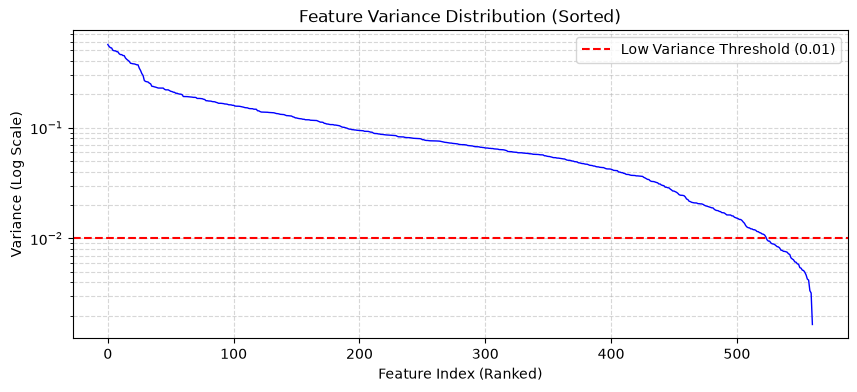

Features with variance < 0.01: 37 out of 561


In [11]:


# --- 1. Visualizing Feature Variance ---
# Calculate variance for each feature and sort them
variances = X_train.var().sort_values(ascending=False)

plt.figure(figsize=(10, 4))
plt.plot(range(len(variances)), variances.values, color='b', lw=1)
plt.yscale('log') # Log scale helps because variance spans multiple orders of magnitude
plt.axhline(y=0.01, color='red', linestyle='--', label='Low Variance Threshold (0.01)')
plt.title("Feature Variance Distribution (Sorted)")
plt.xlabel("Feature Index (Ranked)")
plt.ylabel("Variance (Log Scale)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()

# Count how many fall below threshold
low_var_count = (variances < 0.01).sum()
print(f"Features with variance < 0.01: {low_var_count} out of {X_train.shape[1]}")

Correlation Analysis: We use correlation instead of PCA because features are not selected naively. The items are in different domains

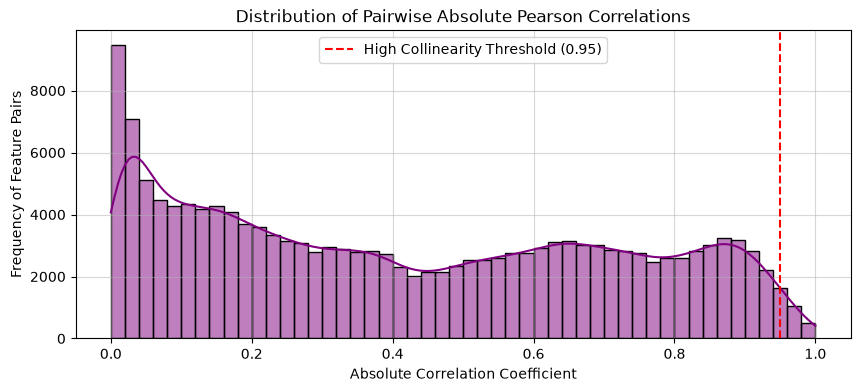

Number of feature pairs with correlation > 0.95: 2281


In [10]:
# --- 2. Visualizing Feature Collinearity ---
# Compute correlation matrix
corr_matrix = X_train.corr().abs()

# Extract upper triangle of correlation matrix to look at pairwise correlations
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
corr_values = upper_tri.unstack().dropna()

plt.figure(figsize=(10, 4))
sns.histplot(corr_values, bins=50, color='purple', kde=True)
plt.axvline(x=0.95, color='red', linestyle='--', label='High Collinearity Threshold (0.95)')
plt.title("Distribution of Pairwise Absolute Pearson Correlations")
plt.xlabel("Absolute Correlation Coefficient")
plt.ylabel("Frequency of Feature Pairs")
plt.legend()
plt.grid(True, alpha=0.5)
plt.show()

# Count how many pairs are highly correlated (> 0.95)
high_corr_pairs = (corr_values > 0.95).sum()
print(f"Number of feature pairs with correlation > 0.95: {high_corr_pairs}")

In [14]:
# --- Cell: Domain-Wise Feature Subsetting ---
import pandas as pd

# Assume X_train_clean is your dataframe of features after collinearity filtering
feature_list = X_train.columns.tolist()

# Define domain keyword dictionaries
domain_groups = {
    "Time_BodyAcc": [f for f in feature_list if f.startswith("tBodyAcc") and "Jerk" not in f and "Mag" not in f],
    "Time_GravityAcc": [f for f in feature_list if f.startswith("tGravityAcc")],
    "Time_BodyAccJerk": [f for f in feature_list if f.startswith("tBodyAccJerk")],
    "Time_BodyGyro": [f for f in feature_list if f.startswith("tBodyGyro") and "Jerk" not in f and "Mag" not in f],
    "Time_BodyGyroJerk": [f for f in feature_list if f.startswith("tBodyGyroJerk")],
    "Magnitudes": [f for f in feature_list if "Mag" in f],
    "Frequency_Domain": [f for f in feature_list if f.startswith("f")]
}

# Print out feature counts per domain subset
print("--- Domain-Wise Feature Breakdown ---")
domain_dataframes = {}
for domain_name, cols in domain_groups.items():
    # Filter only columns that survived the collinearity drop
    valid_cols = [c for c in cols if c in X_train.columns]
    domain_dataframes[domain_name] = X_train[valid_cols]
    print(f"{domain_name:20} -> {len(valid_cols)} features")

--- Domain-Wise Feature Breakdown ---
Time_BodyAcc         -> 40 features
Time_GravityAcc      -> 53 features
Time_BodyAccJerk     -> 53 features
Time_BodyGyro        -> 40 features
Time_BodyGyroJerk    -> 53 features
Magnitudes           -> 117 features
Frequency_Domain     -> 289 features


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# 1. Ensure we are using the full, unreduced feature set
# (Assuming X_train contains all features loaded from features.txt)
feature_list = X_train.columns.tolist()

# 2. Define granular domain groupings based on UCI HAR documentation
domain_groups = {
    "tBodyAcc (Time Body Acc)": [f for f in feature_list if f.startswith("tBodyAcc") and "Jerk" not in f and "Mag" not in f],
    "tGravityAcc (Time Gravity)": [f for f in feature_list if f.startswith("tGravityAcc")],
    "tBodyAccJerk (Time Acc Jerk)": [f for f in feature_list if f.startswith("tBodyAccJerk")],
    "tBodyGyro (Time Gyro)": [f for f in feature_list if f.startswith("tBodyGyro") and "Jerk" not in f and "Mag" not in f],
    "tBodyGyroJerk (Time Gyro Jerk)": [f for f in feature_list if f.startswith("tBodyGyroJerk")],
    "Magnitudes (Euclidean)": [f for f in feature_list if "Mag" in f],
    "Frequency Domain (FFT)": [f for f in feature_list if f.startswith("f")]
}

# 3. Compute intra-domain correlation profiles
domain_insights = []

for domain_name, cols in domain_groups.items():
    if len(cols) > 1:
        sub_df = X_train[cols]
        corr_sub = sub_df.corr().abs()
        
        # Extract upper triangle to get pairwise correlations within this domain
        upper_tri = corr_sub.where(np.triu(np.ones(corr_sub.shape), k=1).astype(bool))
        pairwise_vals = upper_tri.unstack().dropna()
        
        domain_insights.append({
            "Domain": domain_name,
            "Feature Count": len(cols),
            "Mean Intra-Domain Corr": pairwise_vals.mean(),
            "Median Intra-Domain Corr": pairwise_vals.median(),
            "Max Intra-Domain Corr": pairwise_vals.max(),
            "Pairs > 0.95 (%)": (pairwise_vals > 0.95).mean() * 100
        })

insights_df = pd.DataFrame(domain_insights)
print("--- Exploratory Intra-Domain Correlation Profile ---")
print(insights_df.to_string(index=False))

--- Exploratory Intra-Domain Correlation Profile ---
                        Domain  Feature Count  Mean Intra-Domain Corr  Median Intra-Domain Corr  Max Intra-Domain Corr  Pairs > 0.95 (%)
      tBodyAcc (Time Body Acc)             40                0.432020                  0.403388               0.998632          2.948718
    tGravityAcc (Time Gravity)             53                0.299297                  0.266882               1.000000          4.063861
  tBodyAccJerk (Time Acc Jerk)             53                0.454827                  0.334152               1.000000          7.256894
         tBodyGyro (Time Gyro)             40                0.403641                  0.371364               0.997776          1.410256
tBodyGyroJerk (Time Gyro Jerk)             53                0.401010                  0.304138               1.000000          5.732946
        Magnitudes (Euclidean)            117                0.526317                  0.521455               1.000000       

C:\Users\muhat\AppData\Local\Temp\ipykernel_29872\3188879824.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

C:\Users\muhat\AppData\Local\Temp\ipykernel_29872\3188879824.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



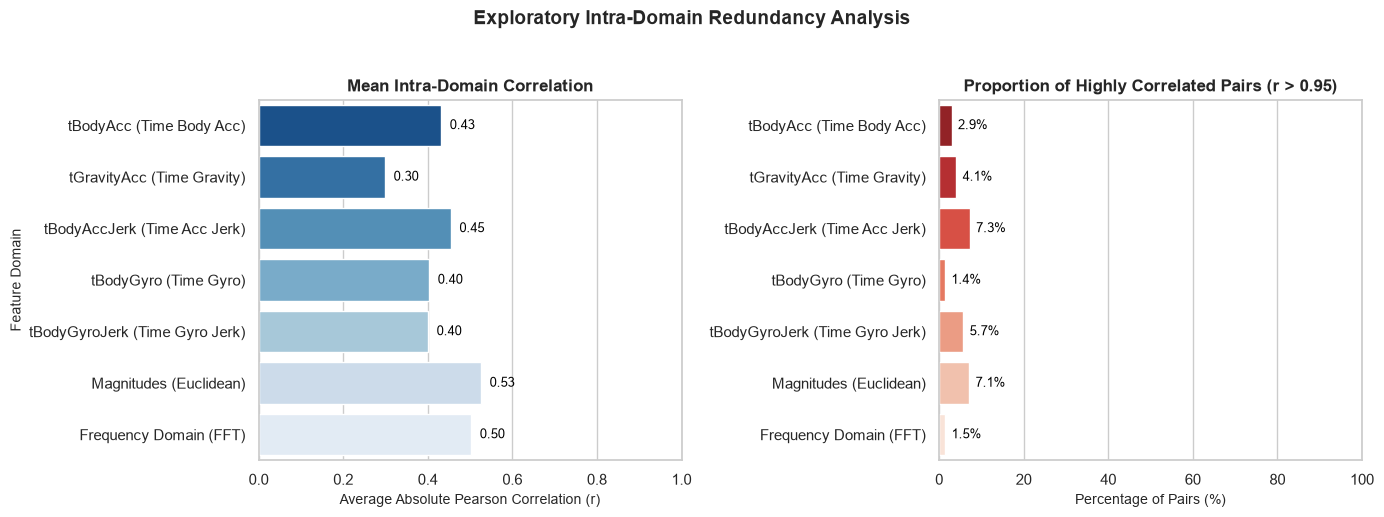

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure insights_df is already generated from your code snippet
# Set style for a clean academic look
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5), sharey=False)

# 1. Plot Mean Intra-Domain Correlation
sns.barplot(
    data=insights_df, 
    y="Domain", 
    x="Mean Intra-Domain Corr", 
    ax=axes[0], 
    palette="Blues_r"
)
axes[0].set_title("Mean Intra-Domain Correlation", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Average Absolute Pearson Correlation (r)", fontsize=10)
axes[0].set_ylabel("Feature Domain", fontsize=10)
axes[0].set_xlim(0, 1.0)

# Add data labels to the bars
for p in axes[0].patches:
    width = p.get_width()
    axes[0].annotate(
        f"{width:.2f}",
        (width + 0.02, p.get_y() + p.get_height() / 2.),
        ha="left", va="center", fontsize=9, color="black"
    )

# 2. Plot Percentage of Redundant Pairs (> 0.95)
sns.barplot(
    data=insights_df, 
    y="Domain", 
    x="Pairs > 0.95 (%)", 
    ax=axes[1], 
    palette="Reds_r"
)
axes[1].set_title("Proportion of Highly Correlated Pairs (r > 0.95)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Percentage of Pairs (%)", fontsize=10)
axes[1].set_ylabel("")
axes[1].set_xlim(0, 100)

# Add data labels to the bars
for p in axes[1].patches:
    width = p.get_width()
    axes[1].annotate(
        f"{width:.1f}%",
        (width + 1.5, p.get_y() + p.get_height() / 2.),
        ha="left", va="center", fontsize=9, color="black"
    )

plt.suptitle("Exploratory Intra-Domain Redundancy Analysis", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

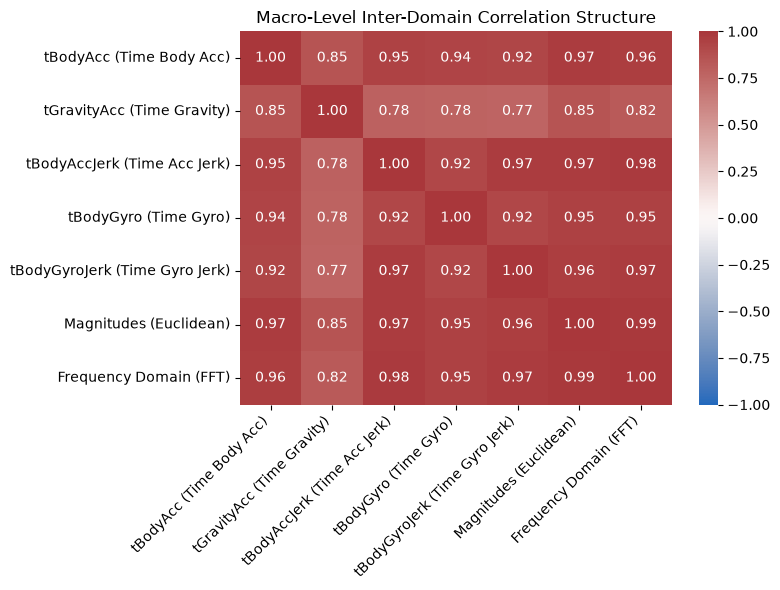

In [16]:
# 4. Compute Inter-Domain Correlation Matrix (Domain-level summary)
domain_mean_vectors = {}
for domain_name, cols in domain_groups.items():
    if len(cols) > 0:
        # Take the mean or first principal component of the domain as a proxy, 
        # or compute average cross-correlation block-by-block
        domain_mean_vectors[domain_name] = X_train[cols].mean(axis=1)

proxy_df = pd.DataFrame(domain_mean_vectors)
domain_corr_matrix = proxy_df.corr()

# Plot macro-level domain interaction
plt.figure(figsize=(8, 6))
sns.heatmap(domain_corr_matrix, annot=True, cmap="vlag", vmin=-1, vmax=1, fmt=".2f")
plt.title("Macro-Level Inter-Domain Correlation Structure")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

C:\Users\muhat\AppData\Local\Temp\ipykernel_29872\3779975606.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
C:\Users\muhat\AppData\Local\Temp\ipykernel_29872\3779975606.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



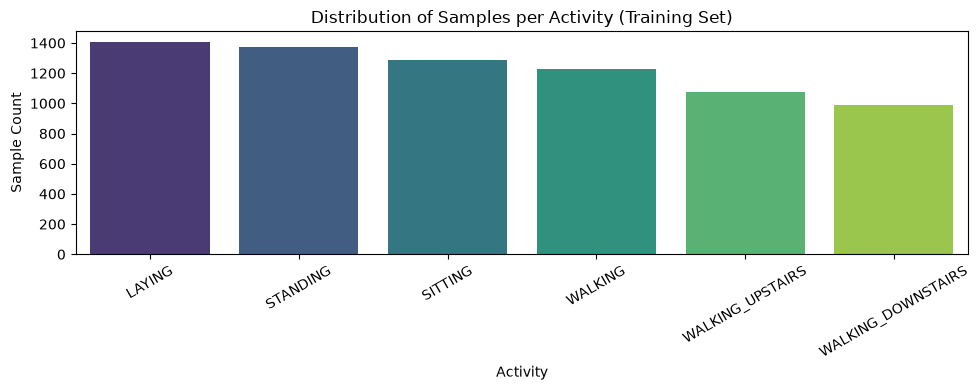

C:\Users\muhat\AppData\Local\Temp\ipykernel_29872\3779975606.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



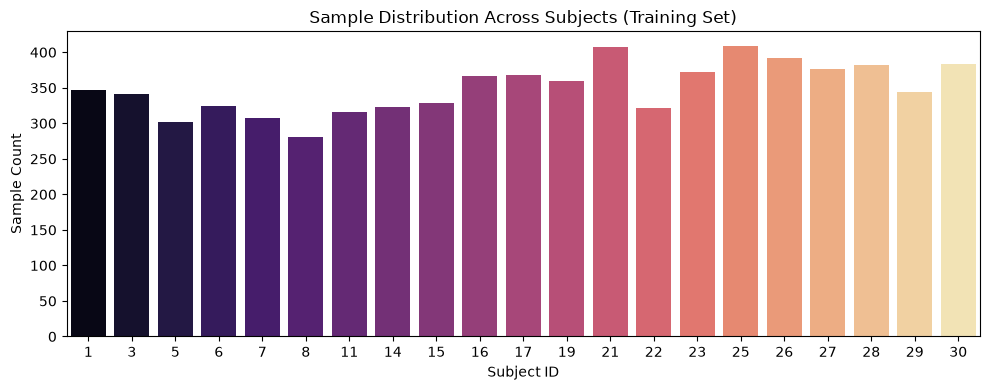

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Map activity IDs to readable names based on UCI HAR documentation
activity_mapping = {
    1: 'WALKING', 
    2: 'WALKING_UPSTAIRS', 
    3: 'WALKING_DOWNSTAIRS', 
    4: 'SITTING', 
    5: 'STANDING', 
    6: 'LAYING'
}
train_df['activity_name'] = train_df['activity_id'].map(activity_mapping)

# --- A. Activity Distribution Check ---
plt.figure(figsize=(10, 4))
ax = sns.countplot(data=train_df, x='activity_name', order=train_df['activity_name'].value_counts().index, palette='viridis')
plt.title("Distribution of Samples per Activity (Training Set)")
plt.xlabel("Activity")
plt.ylabel("Sample Count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# --- B. Subject Representation Check ---
plt.figure(figsize=(10, 4))
sns.countplot(data=train_df, x='subject_id', palette='magma')
plt.title("Sample Distribution Across Subjects (Training Set)")
plt.xlabel("Subject ID")
plt.ylabel("Sample Count")
plt.tight_layout()
plt.show()

C:\Users\muhat\AppData\Local\Temp\ipykernel_29872\3896836969.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



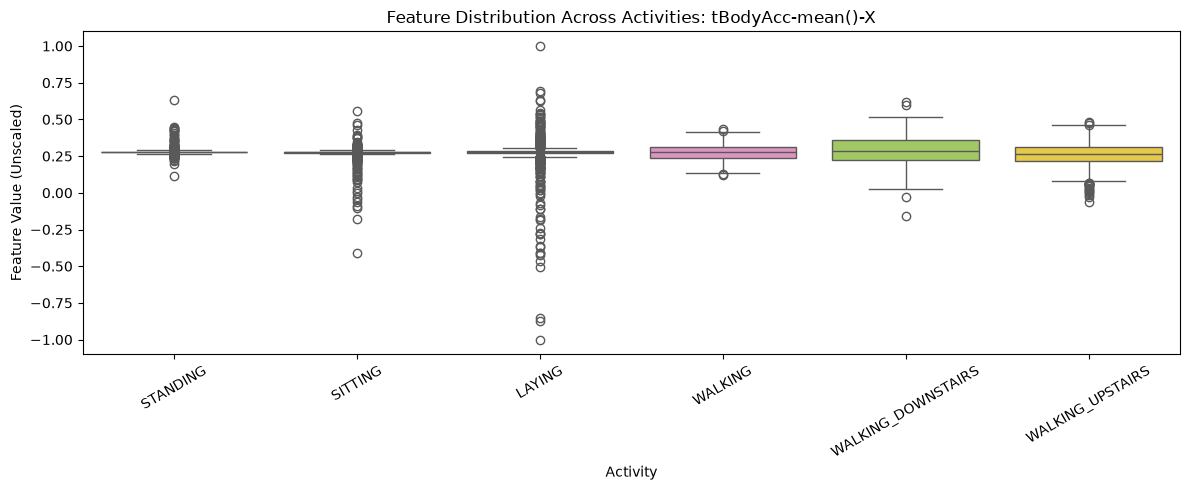

In [18]:
# --- C. Activity Separability via Feature Profiles ---
# Let's look at a magnitude feature or acceleration mean across activities
sample_feature = [c for c in X_train.columns if "tBodyAcc-mean()-X" in c]

if sample_feature:
    plt.figure(figsize=(12, 5))
    sns.boxplot(data=train_df, x='activity_name', y=sample_feature[0], palette='Set2')
    plt.title(f"Feature Distribution Across Activities: {sample_feature[0]}")
    plt.xlabel("Activity")
    plt.ylabel("Feature Value (Unscaled)")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

C:\Users\muhat\AppData\Local\Temp\ipykernel_29872\1325913049.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



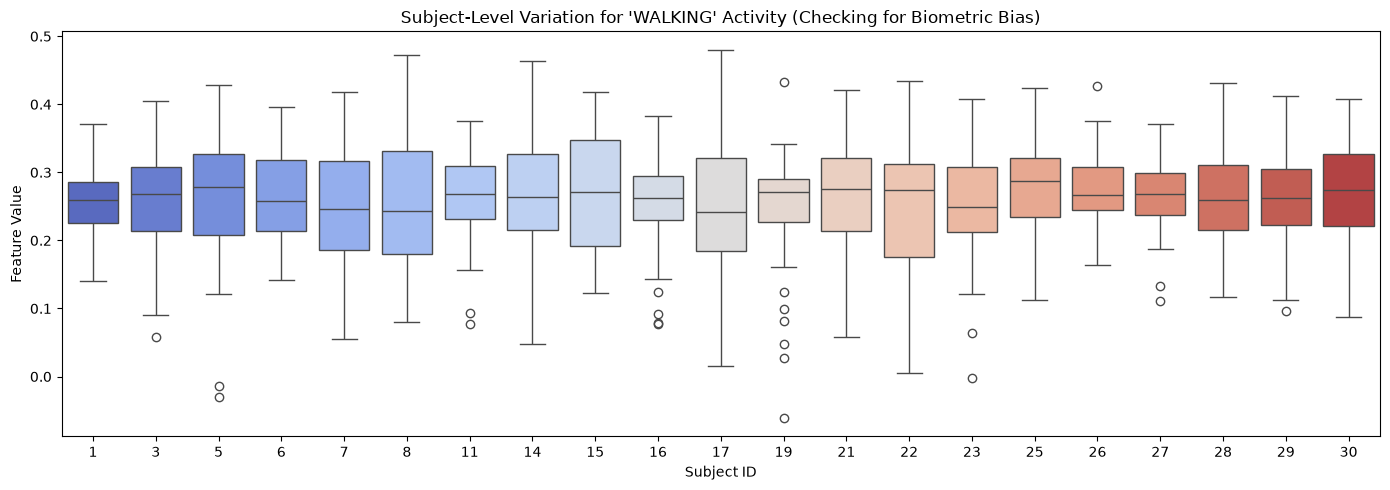

In [25]:
# --- D. Subject Variability within a Single Activity (e.g., WALKING) ---
walking_df = train_df[train_df['activity_name'] == 'WALKING_UPSTAIRS']

plt.figure(figsize=(14, 5))
sns.boxplot(data=walking_df, x='subject_id', y=sample_feature[0] if sample_feature else X_train.columns[0], palette='coolwarm')
plt.title("Subject-Level Variation for 'WALKING' Activity (Checking for Biometric Bias)")
plt.xlabel("Subject ID")
plt.ylabel("Feature Value")
plt.tight_layout()
plt.show()